# 06 Evaluation

In [1]:
# %pip install -q "chromadb>=1,<2" sentence-transformers openai python-dotenv pandas numpy matplotlib tiktoken "mlflow>=3,<4"

## 1. Configuration

In [2]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
BASE = ROOT.parent if ROOT.name == 'notebooks' else ROOT
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from src.evaluation_dataset import make_dataset
from src.evaluation import run_evaluation

RUN_LIVE_EVALUATION = False
API_BUDGET_USD = 5.0
WORKERS = 3
REPORTS = BASE / 'reports'
EVALUATION = REPORTS / 'evaluation'
print('Project:', BASE)
print('Live API calls enabled:', RUN_LIVE_EVALUATION)

Project: c:\Users\ashym\Documents\GitHub\jarvis_data_eng_YashMehrotra\ml_3
Live API calls enabled: False


## 2. Verify steps 4 and 5

In [3]:
verification_path = REPORTS / 'step_4_5_verification.md'
if verification_path.exists():
    display(Markdown(verification_path.read_text(encoding='utf-8')))
else:
    print('Verification report not found. Inspect notebook 4/5 source and saved results before evaluation.')

Verification report not found. Inspect notebook 4/5 source and saved results before evaluation.


## 3. Thirty-question test set and shared references

In [4]:
dataset = make_dataset()
test_table = pd.DataFrame(dataset)
display(test_table[['id','question_type','banks','risk','question']])
display(test_table.groupby('question_type').size().to_frame('questions'))
assert len(dataset) == 30 and len({q['id'] for q in dataset}) == 30

,id,question_type,banks,risk,question
0,eval_01,factual,[RBC],credit,What credit risks and provisions for credit lo...
1,eval_02,factual,[RBC],market,What market risk and Value-at-Risk measures di...
2,eval_03,factual,[RBC],climate,What physical and transition climate risks did...
3,eval_04,factual,[TD],operational,What cybersecurity and operational risks did T...
4,eval_05,factual,[TD],credit,What residential mortgage credit risks did TD ...
5,eval_06,factual,[TD],liquidity,What liquidity and funding risks did TD disclo...
6,eval_07,factual,[BMO],liquidity,What liquidity risk controls and liquidity cov...
7,eval_08,factual,[BMO],market,What interest-rate risk management did BMO dis...
8,eval_09,factual,[BMO],operational,What operational and technology risks did BMO ...
9,eval_10,factual,[BNS],climate,What physical and transition climate risks did...


,questions
question_type,
comparative,5
edge,5
factual,15
trend,5


## 4. Generate, judge and track

In [5]:
if RUN_LIVE_EVALUATION:
    evaluation = run_evaluation(BASE, live=True, workers=WORKERS, budget_usd=API_BUDGET_USD)
    RUN_PATH = evaluation['run_path']
else:
    pointer = EVALUATION / 'latest_run.json'
    if not pointer.exists():
        raise FileNotFoundError('No saved evaluation. Set RUN_LIVE_EVALUATION=True to run generation and judging.')
    latest = json.loads(pointer.read_text(encoding='utf-8'))
    RUN_PATH = EVALUATION / latest['run_id']
    print('Loading saved evaluation; no generation/judge calls made.')

manifest = json.loads((RUN_PATH/'manifest.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(RUN_PATH/'master_comparison.csv')
metrics = pd.read_csv(RUN_PATH/'per_question_metrics.csv')
cases = [json.loads(path.read_text(encoding='utf-8')) for path in sorted((RUN_PATH/'cases').glob('*.json'))]
print('Evaluation:', manifest['run_id'])
print('Reports:', RUN_PATH)
print('Scored cases:', int(metrics['status'].eq('complete').sum()), '/ 90')
display(comparison)

Loading saved evaluation; no generation/judge calls made.
Evaluation: 54a68bec798eab0e
Reports: c:\Users\ashym\Documents\GitHub\jarvis_data_eng_YashMehrotra\ml_3\reports\evaluation\54a68bec798eab0e
Scored cases: 90 / 90


,config,expected_questions,scored_questions,error_questions,complete,faithfulness,relevance,completeness,hallucination_risk_count,hallucination_risk_rate,mean_latency_seconds,p95_latency_seconds,mean_embedding_cost_usd,mean_retrieval_cost_usd,mean_generation_cost_usd,mean_cost_per_query_usd,annual_cost_1000_per_day_usd,judge_total_cost_usd,meets_quality_target
0,basic_top_k,30,30,0,True,4.533333,4.600000,4.333333,1,0.033333,5.185797,9.702927,0.0,0.0,0.000748,0.000748,272.970725,0.052099,True
1,mmr_structured,30,30,0,True,4.566667,4.666667,4.433333,1,0.033333,6.486931,12.013546,0.0,0.0,0.000768,0.000768,280.493375,0.050362,True
2,agentic,30,30,0,True,4.566667,4.633333,4.333333,1,0.033333,15.555392,37.951113,0.0,0.0,0.001503,0.001503,548.741000,0.056692,True


## 5. Master comparison and quality thresholds

,config,scored_questions,complete,faithfulness,relevance,completeness,hallucination_risk_count,meets_quality_target
0,basic_top_k,30,True,4.533333,4.600000,4.333333,1,True
1,mmr_structured,30,True,4.566667,4.666667,4.433333,1,True
2,agentic,30,True,4.566667,4.633333,4.333333,1,True


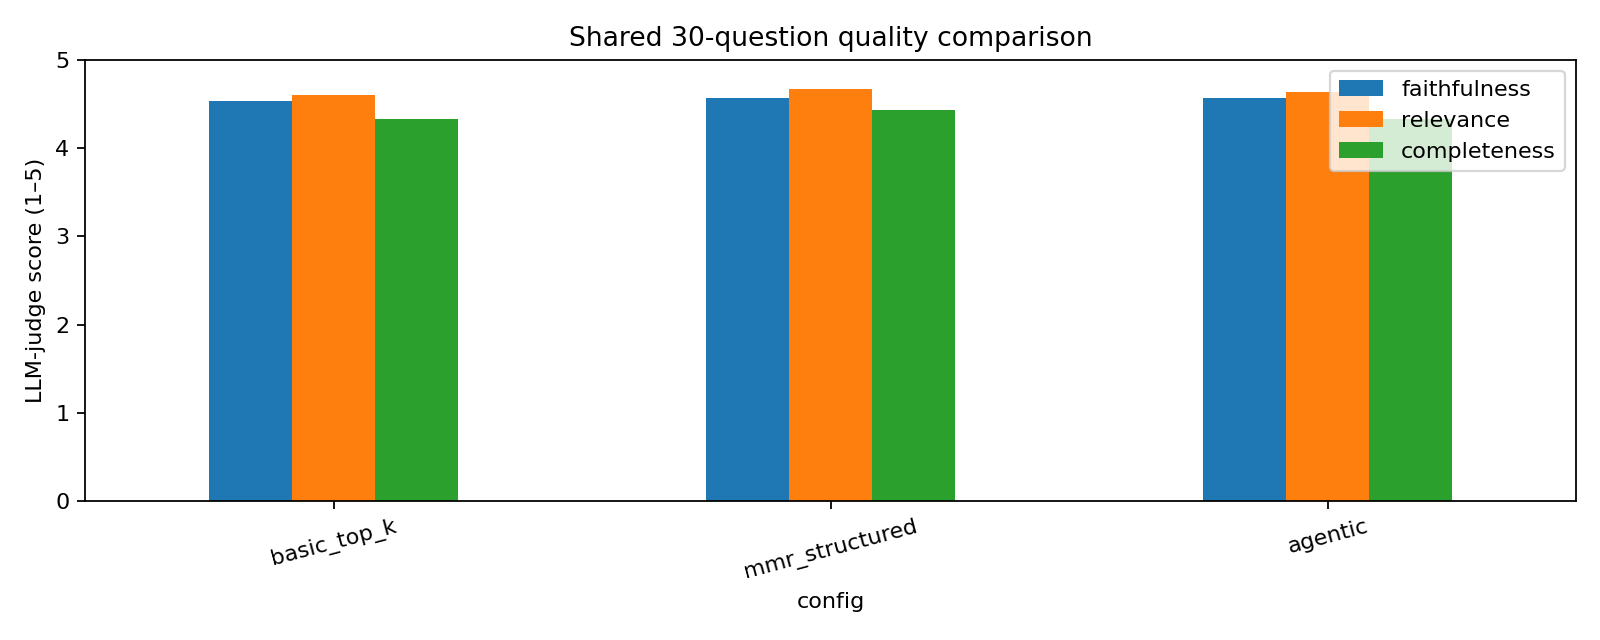

faithfulness  relevance  completeness
config         question_type                                       
agentic        comparative             4.2   4.000000      3.000000
               edge                    3.8   4.000000      3.800000
               factual                 5.0   5.000000      5.000000
               trend                   4.4   4.800000      4.200000
basic_top_k    comparative             4.2   4.200000      3.200000
               edge                    4.6   4.800000      4.800000
               factual                 4.6   4.533333      4.533333
               trend                   4.6   5.000000      4.400000
mmr_structured comparative             3.8   4.000000      3.000000
               edge                    4.4   4.400000      4.400000
               factual                 5.0   5.000000      5.000000
               trend                   4.2   4.600000      4.200000

faithfulness  relevance  completeness
config         risk                                              
agentic        ambiguous        3.000000   4.000000      3.000000
               calculation      5.000000   5.000000      5.000000
               climate          4.500000   4.500000      4.000000
               credit           4.363636   4.454545      4.181818
               liquidity        4.600000   4.800000      4.400000
               market           5.000000   5.000000      5.000000
               model_risk       5.000000   4.000000      3.000000
               operational      5.000000   5.000000      5.000000
basic_top_k    ambiguous        3.000000   4.000000      4.000000
               calculation      5.000000   5.000000      5.000000
               climate          4.250000   4.000000      3.750000
               credit           4.818182   4.818182      4.636364
               liquidity        4.400000   4.800000      4.000000
               market           3.666667   3.666667      3.666667
               model_risk       5.000000   5.000000      4.000000
               operational      5.000000   5.000000      5.000000
mmr_structured ambiguous        2.000000   2.000000      2.000000
               calculation      5.000000   5.000000      5.000000
               climate          4.250000   4.500000      4.000000
               credit           4.636364   4.727273      4.454545
               liquidity        4.800000   4.800000      4.600000
               market           5.000000   5.000000      5.000000
               model_risk       3.000000   4.000000      3.000000
               operational      5.000000   5.000000      5.000000

In [6]:
quality_columns = [c for c in ['config','scored_questions','complete','faithfulness','relevance',
    'completeness','hallucination_risk_count','meets_quality_target'] if c in comparison]
display(comparison[quality_columns])
if (RUN_PATH/'quality_comparison.png').exists():
    display(Image(filename=str(RUN_PATH/'quality_comparison.png')))
for dimension in ['question_type','risk']:
    scored = metrics[metrics['status']=='complete']
    if not scored.empty:
        display(scored.groupby(['config',dimension])[['faithfulness','relevance','completeness']].mean())

## 6. Hallucination analysis and source inspection

In [7]:
hallucinations = json.loads((RUN_PATH/'hallucination_cases.json').read_text(encoding='utf-8'))
print('Flagged grounding-risk cases:', len(hallucinations))
for case in hallucinations:
    print(case['config'], case['question']['id'], case['question']['question'])
    print(case['judgment']['faithfulness_reason'])
display(Markdown((RUN_PATH/'hallucination_analysis.md').read_text(encoding='utf-8')))

# Choose one record to inspect. Keep the same case ID when recording a human review.
CASE_CONFIG, QUESTION_ID = 'agentic', 'eval_01'
selected = next((c for c in cases if c['config']==CASE_CONFIG and c['question']['id']==QUESTION_ID), None)
if selected and 'generation' in selected:
    print('QUESTION:', selected['question']['question'])
    print('ANSWER:', selected['generation']['answer'])
    display(selected.get('judgment', {}))
    for hit in selected['generation']['sources']:
        print('\n', hit['chunk_id'], hit.get('source_url'), hit.get('page_start'), hit.get('page_end'))
        print(hit['text'])

Flagged grounding-risk cases: 3
agentic eval_26 What were Bank of Atlantis credit losses in 2025?
The answer refers to credit losses for Scotiabank instead of the requested Bank of Atlantis, which is outside the corpus. Therefore, the claims are not supported by the correct bank context.
basic_top_k eval_08 What interest-rate risk management did BMO disclose in its 2025 annual report?
The answer claims insufficient information to address the question, which is accurate given the lack of specific disclosures on interest-rate risk management in the provided context.
mmr_structured eval_28 Did the bank improve its risk profile?
The claim that the Toronto-Dominion Bank improved its risk profile is not fully supported by the evidence provided. While the update to the Enterprise Risk Framework is mentioned, the context does not explicitly state that this constitutes an improvement in the risk profile, leading to a material unsupported claim.


# Hallucination case analysis

Faithfulness ≤2 flags a material grounding risk under the LLM rubric. These cases require human confirmation.

## agentic eval_26

Question: What were Bank of Atlantis credit losses in 2025?

Faithfulness: 1/5. The answer refers to credit losses for Scotiabank instead of the requested Bank of Atlantis, which is outside the corpus. Therefore, the claims are not supported by the correct bank context.

Unsupported claims: 

Evidence inspected: BNS_2025_annual_report_FY_00066, BNS_2025_annual_report_FY_00389, BNS_2025_annual_report_FY_00060, BNS_2025_annual_report_FY_00390, BNS_2025_AIF_FY_00044, BNS_2025_AIF_FY_00041, BNS_2025_AIF_FY_00022, BNS_2025_AIF_FY_00042, BNS_2025_quarterly_Q1_00129, BNS_2025_quarterly_Q1_00134, BNS_2025_quarterly_Q1_00130, BNS_2025_quarterly_Q1_00133, BNS_2025_quarterly_Q2_00146, BNS_2025_quarterly_Q2_00062, BNS_2025_quarterly_Q2_00152, BNS_2025_quarterly_Q2_00045, BNS_2025_quarterly_Q3_00150, BNS_2025_quarterly_Q3_00054, BNS_2025_quarterly_Q3_00151, BNS_2025_quarterly_Q3_00035

Observed routing failure: the question names unsupported Bank of Atlantis, but the agent answered with Scotiabank figures. An unrestricted tool search substituted another bank. Add an explicit unknown-bank gate and verify the final answer entity against the requested bank before returning it.The judge explanation identifies the specific claim; confirm it against the saved context before assigning a definitive cause.

Remediation: require supporting citations for each disputed claim, retrieve missing banks/periods, and use deterministic arithmetic with cited inputs; abstain when either input is absent.

## basic_top_k eval_08

Question: What interest-rate risk management did BMO disclose in its 2025 annual report?

Faithfulness: 1/5. The answer claims insufficient information to address the question, which is accurate given the lack of specific disclosures on interest-rate risk management in the provided context.

Unsupported claims: 

Evidence inspected: BMO_2025_annual_report_FY_00124, BMO_2025_annual_report_FY_00021, BMO_2025_annual_report_FY_00143, BMO_2025_annual_report_FY_00189, BMO_2025_annual_report_FY_00237

Judge inconsistency: this is the fixed insufficient-information refusal, with no affirmative financial claim. The rubric assigns a faithful refusal 5 even when completeness is low. Treat this flag as a likely grader false positive; retain the raw score and request independent adjudication.The judge explanation identifies the specific claim; confirm it against the saved context before assigning a definitive cause.

Remediation: require supporting citations for each disputed claim, retrieve missing banks/periods, and use deterministic arithmetic with cited inputs; abstain when either input is absent.

## mmr_structured eval_28

Question: Did the bank improve its risk profile?

Faithfulness: 2/5. The claim that the Toronto-Dominion Bank improved its risk profile is not fully supported by the evidence provided. While the update to the Enterprise Risk Framework is mentioned, the context does not explicitly state that this constitutes an improvement in the risk profile, leading to a material unsupported claim.

Unsupported claims: The bank improved its risk profile without sufficient evidence to support this claim.; The assertion of a proactive approach to risk management is not substantiated by the evidence provided.

Evidence inspected: TD_2025_quarterly_Q3_00095, BNS_2024_quarterly_Q3_00074, TD_2025_annual_report_FY_00314, TD_2024_annual_report_FY_00325, BNS_2024_quarterly_Q2_00006

Ambiguity handling needs review: the request specifies neither bank nor period. Retrieval and synthesis can select an arbitrary institution instead of asking for clarification. Add a clarification route before retrieval and assess the saved answer against this expected behavior.The judge explanation identifies the specific claim; confirm it against the saved context before assigning a definitive cause.

Remediation: require supporting citations for each disputed claim, retrieve missing banks/periods, and use deterministic arithmetic with cited inputs; abstain when either input is absent.


QUESTION: What credit risks and provisions for credit losses did RBC disclose in its 2025 annual report?
ANSWER: In RBC's 2025 annual report, the following credit risks and provisions for credit losses were disclosed:

1. **Credit Risk Assessment**: RBC considers credit risk to be low for instruments with a low risk of default and the borrower's ability to meet obligations. The assessment includes forward-looking information and macroeconomic variables such as unemployment rates and GDP growth.

2. **Expected Credit Losses (ECL)**: The ECL measurement involves significant judgment and is based on a discounted probability-weighted estimate considering multiple macroeconomic scenarios. The bank uses parameters like Probability of Default (PD), Loss Given Default (LGD), and Exposure at Default (EAD) to estimate credit losses.

3. **Stages of Credit Losses**: Credit losses are categorized into three stages:
   - **Stage 1**: Performing assets with expected losses over 12 months.
   - **Sta

{'faithfulness': 5,
 'relevance': 5,
 'completeness': 5,
 'faithfulness_reason': "All claims about credit risks and provisions for credit losses are supported by the actual answer context from RBC's 2025 annual report, including specific details about credit risk assessment, expected credit losses, stages of credit losses, provisions for credit losses, and management of credit risk.",
 'relevance_reason': 'The answer directly addresses the question regarding credit risks and provisions for credit losses disclosed by RBC in its 2025 annual report.',
 'completeness_reason': 'The answer comprehensively covers all aspects of the requested information, including specific categories and details of credit risks and provisions for credit losses as disclosed in the report.',
 'unsupported_claims': [],
 'reference_limitations': ''}


 RBC_2025_annual_report_FY_00280 https://www.rbc.com/investor-relations/_assets-custom/pdf/ar_2025_e.pdf 156 156
Credit risk is considered to be low if the instrument has a low risk of default, and the
borrower has the ability to fulfill their contractual obligations both in the near term and in the longer term, including periods of
adverse changes in the economic or business environment. Certain interest-bearing deposits with banks, assets purchased
under reverse repurchase agreements, insurance policy loans, and liquidity facilities extended to our multi-seller conduits have
been identified as having low credit risk. Use of forward-looking information
The measurement of expected credit losses for each stage and the assessment of significant increase in credit risk considers
information about past events and current conditions as well as reasonable and supportable projections of future events and
economic conditions. The estimation and application of forward-looking information requi

## 7. Cost per query and annual projection

,config,mean_embedding_cost_usd,mean_retrieval_cost_usd,mean_generation_cost_usd,mean_cost_per_query_usd,annual_cost_1000_per_day_usd,judge_total_cost_usd,mean_latency_seconds,p95_latency_seconds
0,basic_top_k,0.0,0.0,0.000748,0.000748,272.970725,0.052099,5.185797,9.702927
1,mmr_structured,0.0,0.0,0.000768,0.000768,280.493375,0.050362,6.486931,12.013546
2,agentic,0.0,0.0,0.001503,0.001503,548.741000,0.056692,15.555392,37.951113


{'gpt-4o-mini': {'input': 0.15, 'cached_input': 0.075, 'output': 0.6},
 'text-embedding-3-small': {'input': 0.02}}

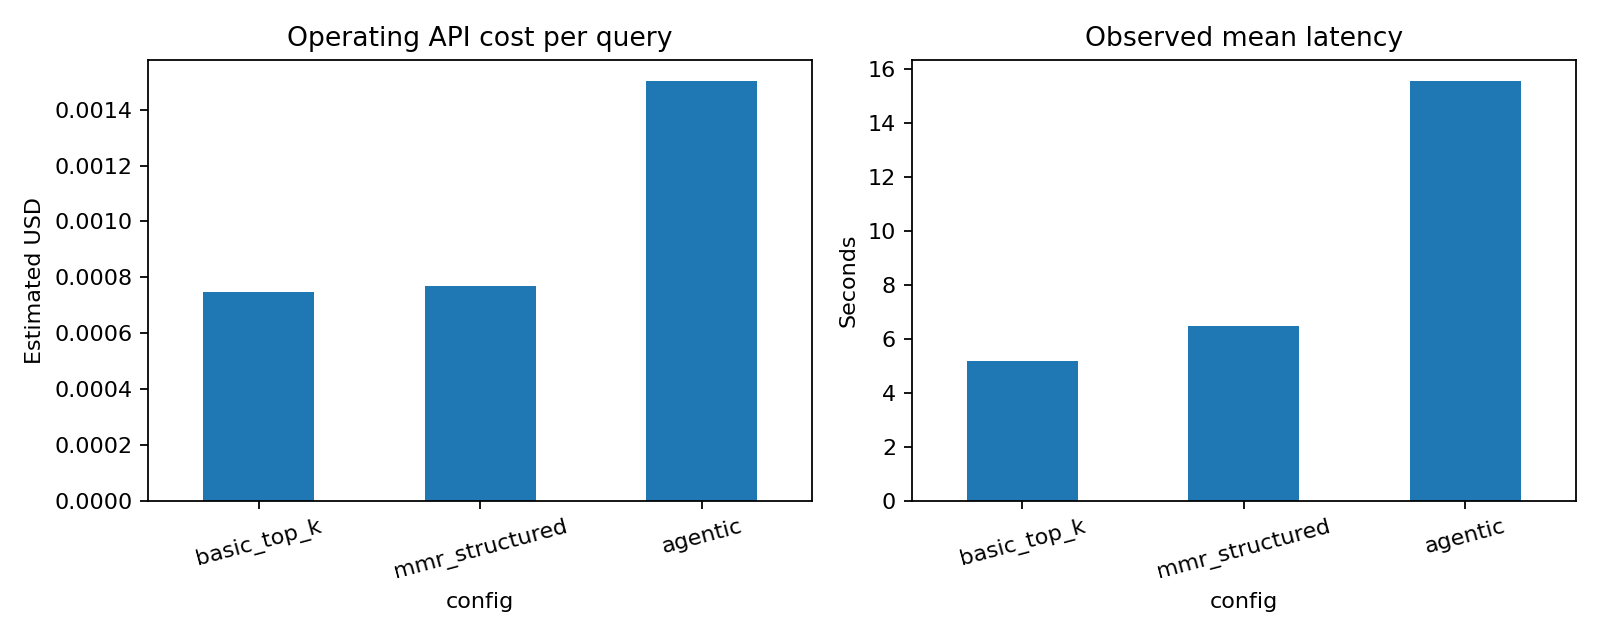

API ledger: c:\Users\ashym\Documents\GitHub\jarvis_data_eng_YashMehrotra\ml_3\reports\evaluation\api_usage.jsonl


In [8]:
cost_columns = [c for c in ['config','mean_embedding_cost_usd','mean_retrieval_cost_usd',
    'mean_generation_cost_usd','mean_cost_per_query_usd','annual_cost_1000_per_day_usd',
    'judge_total_cost_usd','mean_latency_seconds','p95_latency_seconds'] if c in comparison]
display(comparison[cost_columns])
display(manifest['prices_per_million_usd'])
if (RUN_PATH/'cost_latency.png').exists():
    display(Image(filename=str(RUN_PATH/'cost_latency.png')))
print('API ledger:', EVALUATION/'api_usage.jsonl')

## 8. MLflow experiments

Each complete configuration has a tracked run in `models/mlflow.db`, including quality/cost/latency metrics, settings, source/test hashes, rubric and case artifacts.

In [9]:
tracking_file = RUN_PATH/'mlflow_runs.json'
if tracking_file.exists():
    display(pd.DataFrame(json.loads(tracking_file.read_text(encoding='utf-8'))))
else:
    print('No complete configuration logged yet. Complete the run before claiming MLflow comparison.')

,config,run_id
0,basic_top_k,f4f3cb4822184646b7411e114d77c210
1,mmr_structured,6e5a69e8fa264472ab0df4887c3b259c
2,agentic,3d3ce32953e24d329c6a3ebb066fc641
